# Automated Multi-Source Data Validation & Process Quality Workbench
Interactive audit notebook connected to local PostgreSQL (`registration_dq`).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path('..').resolve()))

import pandas as pd
import matplotlib.pyplot as plt
from src.db import get_conn
from benchmark import run_benchmark

In [2]:
metrics = run_benchmark(batch_id='notebook_audit_v1', n_clean=1800)
pd.Series(metrics)

benchmark_batch                                                             notebook_audit_v1
total_records_ingested                                                                   1940
ground_truth_clean                                                                       1800
ground_truth_injected_defects                                                             140
defects_quarantined_by_framework                                                          141
defects_escaped                                                                             0
defect_detection_recall_pct                                                            100.71
unvalidated_reporting_error_rate_pct                                                     7.22
post_validation_reporting_error_rate_pct                                                  0.0
reporting_error_reduction_pct                                                           100.0
breakdown                                   {'duplicates_cau

In [3]:
with get_conn() as conn:
    q_df = pd.read_sql(
        "SELECT source_system, rule_id, severity, COUNT(*) AS quarantined_count "
        "FROM quarantine_records GROUP BY 1, 2, 3 ORDER BY quarantined_count DESC",
        conn,
    )
    run_df = pd.read_sql("SELECT * FROM dq_validation_runs", conn)

display(q_df)
print(run_df.loc[0, 'ai_triage_summary'])

C:\Users\omart\AppData\Local\Temp\ipykernel_39828\72034118.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  q_df = pd.read_sql(
C:\Users\omart\AppData\Local\Temp\ipykernel_39828\72034118.py:7: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  run_df = pd.read_sql("SELECT * FROM dq_validation_runs", conn)


,source_system,rule_id,severity,quarantined_count
0,source_system,rule_id,severity,quarantined_count
1,source_system,rule_id,severity,quarantined_count
2,source_system,rule_id,severity,quarantined_count
3,source_system,rule_id,severity,quarantined_count
4,source_system,rule_id,severity,quarantined_count
5,source_system,rule_id,severity,quarantined_count
6,source_system,rule_id,severity,quarantined_count


ai_triage_summary


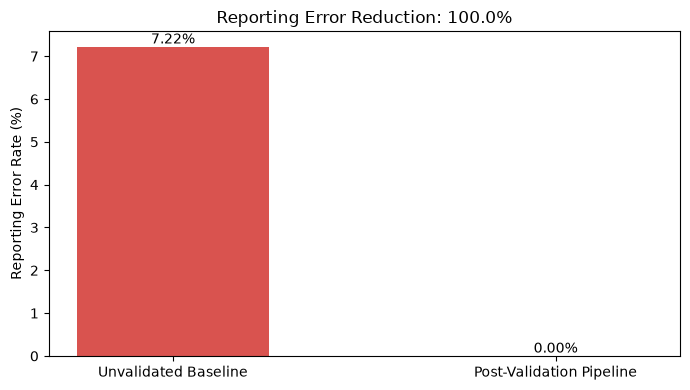

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
labels = ['Unvalidated Baseline', 'Post-Validation Pipeline']
rates = [
    metrics['unvalidated_reporting_error_rate_pct'],
    metrics['post_validation_reporting_error_rate_pct'],
]
bars = ax.bar(labels, rates, color=['#d9534f', '#2e7d32'], width=0.5)
ax.set_ylabel('Reporting Error Rate (%)')
ax.set_title(f"Reporting Error Reduction: {metrics['reporting_error_reduction_pct']}%")
ax.bar_label(bars, fmt='%.2f%%')
plt.tight_layout()
plt.show()